In [108]:
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
from torch.autograd import Variable
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import train_test_split
from collections import Counter

import numpy as np
import os
import pandas as pd
import re
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
%matplotlib inline

In [109]:
# 1. Load the data
df = pd.read_csv('../data/blooms_taxonomy_dataset.csv', encoding='latin-1')

# 2. Clean text function (Lowercase and remove non-alphanumeric)
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)
    return text

df["Questions"] = df["Questions"].apply(clean_text)

# 3. Build Vocabulary (Pure Python/PyTorch approach)
# Count all words in your dataset
all_words = " ".join(df["Questions"]).split()
word_counts = Counter(all_words)

# Create mapping: 0 = Padding, 1 = Unknown, 2+ = Words
# We only take words that appear at least once
vocab = {word: i+2 for i, (word, _) in enumerate(word_counts.most_common())}
vocab["<PAD>"] = 0
vocab["<UNK>"] = 1

# 4. Numericalize Text function
def text_to_sequence(text, vocab, max_len=50):
    tokens = text.split()
    # Convert word to its index in vocab, or 1 if it doesn't exist
    sequence = [vocab.get(word, 1) for word in tokens]
    
    # Pad or Truncate to fixed length
    if len(sequence) < max_len:
        sequence += [0] * (max_len - len(sequence)) # Add zeros to the end
    else:
        sequence = sequence[:max_len] # Cut off the end
    return sequence

# 5. Encode labels (Category -> Integer)
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df["Category"])
num_classes = len(le.classes_)

# 6. Prepare Final Lists
X_data = [text_to_sequence(t, vocab) for t in df["Questions"]]
y_data = df['label_encoded'].tolist()

# 7. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42, stratify=y_data
)

In [110]:
class BloomsDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = torch.LongTensor(sequences)
        self.labels = torch.LongTensor(labels)
        
    def __len__(self):
        return len(self.sequences)
    
    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]

train_dataset = BloomsDataset(X_train, y_train)
test_dataset = BloomsDataset(X_test, y_test)


train_loader = DataLoader(
    train_dataset, 
    batch_size=32, 
    shuffle=True
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=32, 
    shuffle=False
)

print(f"Vocabulary Size: {len(vocab)}")
print(f"Number of Classes: {num_classes}")


Vocabulary Size: 10718
Number of Classes: 6


In [111]:
#NN
class Net(nn.Module):
    def __init__(self, vocab_size, num_classes = 6, embedding_dim = 100):
        super(Net, self).__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        # self.conv1 = nn.Conv1d(in_channels=embedding_dim, out_channels=64, kernel_size= 3, padding=1)
        # self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size= 3, padding=1)
        #parellel convoloution
        self.conv2 = nn.Conv1d(embedding_dim, 100, kernel_size=2)
        self.conv3 = nn.Conv1d(embedding_dim, 100, kernel_size=3)
        self.conv4 = nn.Conv1d(embedding_dim, 100, kernel_size=4)

        # self.pool = nn.AdaptiveMaxPool1d(1)
        self.dropout = nn.Dropout(p = 0.7)

        self.fc = nn.Linear(300, num_classes)

    def forward(self, x):
        # x = self.embedding(x)
        # # PyTorch Conv1d expects channels as the 2nd dimension, so we swap (permute)
        # x = x.permute(0, 2, 1)

        # x = F.relu(self.conv1(x))
        # x = F.relu(self.conv2(x))

        x = self.embedding(x).permute(0, 2, 1)
        
        # Apply ReLU to each parallel conv, then Global Max Pool
        x2 = F.relu(self.conv2(x))
        x2 = F.adaptive_max_pool1d(x2, 1).squeeze(-1)
        
        x3 = F.relu(self.conv3(x))
        x3 = F.adaptive_max_pool1d(x3, 1).squeeze(-1)
        
        x4 = F.relu(self.conv4(x))
        x4 = F.adaptive_max_pool1d(x4, 1).squeeze(-1)

        # p2 = F.adaptive_max_pool1d(x2, 1).squeeze(-1) + F.adaptive_avg_pool1d(x2, 1).squeeze(-1)
        # p3 = F.adaptive_max_pool1d(x3, 1).squeeze(-1) + F.adaptive_avg_pool1d(x3, 1).squeeze(-1)
        # p4 = F.adaptive_max_pool1d(x4, 1).squeeze(-1) + F.adaptive_avg_pool1d(x4, 1).squeeze(-1)

        combined = torch.cat((x2, x3, x4), dim=1)
        # combined = torch.cat((p2, p3, p4), dim=1)
        
        out = self.dropout(combined)
        return self.fc(out)


print("model defined")


model defined


In [112]:
#training an tetsing
def train(model, device, train_loader, optimizer, epoch):
    model.train()
    train_loss = 0
    print("epoch", epoch)

    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)

        optimizer.zero_grad()
        output = model(data)
        loss = loss_criteria(output, target)
        train_loss += loss.item()

        loss.backward()
        optimizer.step()

        if batch_idx %10 == 0:
            print('Training set [{}/{} ({:.0f}%)] Loss: {:.6f}'.format(
                batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))
            
    avg_loss = train_loss /(batch_idx + 1)
    print("avg loss {:.6f}".format(avg_loss))
    return avg_loss

def test(model, device, test_loader):
    model.eval()
    correct = 0
    test_loss = 0
    with torch.no_grad():
        batch_count = 0
        for data, target in test_loader:
            batch_count +=1
            data, target = data.to(device), target.to(device)
            output  = model(data)
            test_loss += loss_criteria(output, target).item()
            _, predicted = torch.max(output.data, 1)
            correct += torch.sum(target==predicted).item()

    avg_loss = test_loss / len(test_loader) 
    acc_pct = 100. * correct / len(test_loader.dataset)

    print('Validation set: Average loss: {:.6f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        avg_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))
    
    return avg_loss, acc_pct

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Training on", device)

model = Net(vocab_size=len(vocab), num_classes=num_classes).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4)#to prevent overfiiting added weight decay
loss_criteria = nn.CrossEntropyLoss()

epoch_nums = []
training_loss = []
validation_loss = []
accuracy_history = []
epochs = 10

scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

for epoch in range(1, epochs + 1):
    # Train the model
    train_loss = train(model, device, train_loader, optimizer, epoch)
    
    test_loss, test_acc = test(model, device, test_loader)
    scheduler.step()
    
    epoch_nums.append(epoch)
    training_loss.append(train_loss)
    validation_loss.append(test_loss)
    accuracy_history.append(test_acc)
    
    print(f'Epoch {epoch}: Train Loss: {train_loss:.4f}, Test Acc: {test_acc:.2f}%')

print(f"\nComplete. Highest Accuracy: {max(accuracy_history):.2f}%")



Training on mps
epoch 1
Training set [0/11877 (0%)] Loss: 2.229864
Training set [320/11877 (3%)] Loss: 1.714374
Training set [640/11877 (5%)] Loss: 1.841026
Training set [960/11877 (8%)] Loss: 1.536430
Training set [1280/11877 (11%)] Loss: 1.580931
Training set [1600/11877 (13%)] Loss: 1.992626
Training set [1920/11877 (16%)] Loss: 1.527293
Training set [2240/11877 (19%)] Loss: 1.626506
Training set [2560/11877 (22%)] Loss: 1.752582
Training set [2880/11877 (24%)] Loss: 1.533469
Training set [3200/11877 (27%)] Loss: 1.690924
Training set [3520/11877 (30%)] Loss: 1.779802
Training set [3840/11877 (32%)] Loss: 1.668378
Training set [4160/11877 (35%)] Loss: 1.344280
Training set [4480/11877 (38%)] Loss: 1.514597
Training set [4800/11877 (40%)] Loss: 1.270794
Training set [5120/11877 (43%)] Loss: 1.372473
Training set [5440/11877 (46%)] Loss: 1.745927
Training set [5760/11877 (48%)] Loss: 1.421537
Training set [6080/11877 (51%)] Loss: 1.623544
Training set [6400/11877 (54%)] Loss: 1.197305

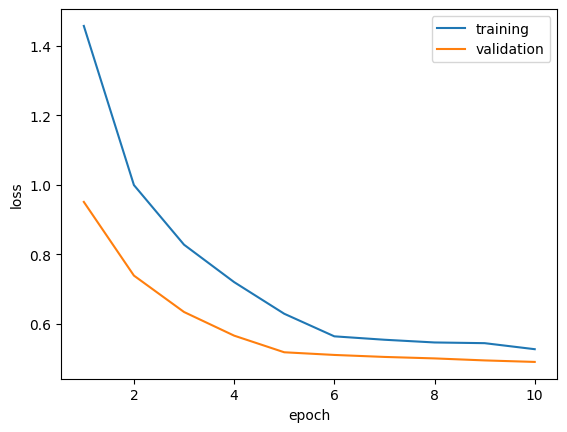

In [114]:
%matplotlib inline
from matplotlib import pyplot as plt

plt.plot(epoch_nums, training_loss)
plt.plot(epoch_nums, validation_loss)
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['training', 'validation'], loc='upper right')
plt.show()